# W10B · B · 실제 SD 기록·새 조건·SDXL 프로젝트

2026-11-04 · 『핸즈온 생성형 AI』7장 전체 · 패키지0.1.17 / 2026-fall-w10b

Drive에 새 사본을 저장하고 첫 셀부터 독립 실행하세요. 다른 노트북의 변수·파일·어댑터, API키·개인 사진·유료 GPU는 필수가 아닙니다. 다운로드/실행 실패를 가짜 결과로 대체하지 않습니다. 설치한 이전 버전을 import했다면 런타임을 재시작합니다.

예측 → 중간값 → 한 조건 변경 → 근거·한계 → 코드 없는 새 사례 설명을 기록합니다. `my_...=None`은 독립 연습 변수라 기본 흐름을 막지 않습니다.

[강의노트](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10b/course/notion/w10b/w10b-lesson.md) · [기록지·점검](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10b/course/notion/w10b/w10b-workbook.md) · [실제 API 정의](https://github.com/lunalab-ai/genAI/blob/2026-fall-w10b/src/W10B-API.md)

필수 CPU 경로는 실제 SD1.5 사전 실행 기록 분석입니다. 여기서 SD를 새로 생성·학습했다고 쓰지 않습니다. 실제 tokenizer 파일은 최초 자동 다운로드 후 캐시 재사용하며 SD 가중치 약2.6GB는 선택 live 경로에서만 받습니다. SDXL은 데이터·명령 준비와 구조 계산까지 필수이며 실제 GPU 학습은 선택·장치별 미검증입니다.

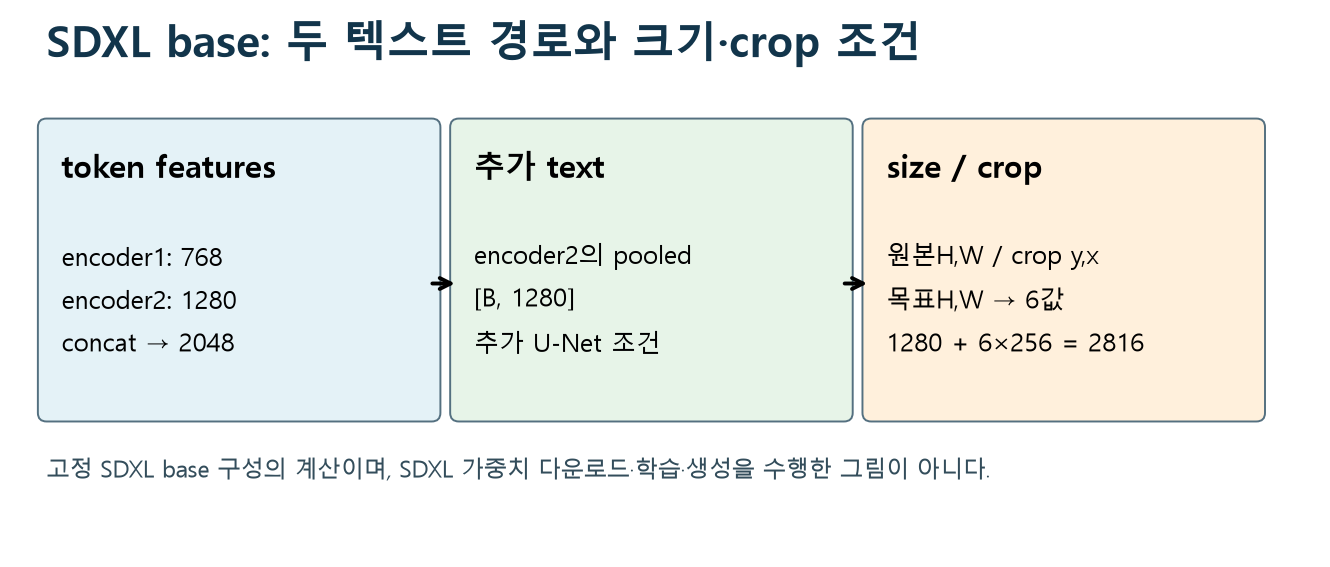


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w10b/course/notion/w10b/assets/09-sdxl-conditions.png)


In [ ]:
import sys,subprocess,os,json,time,uuid
from pathlib import Path
from importlib.metadata import version,PackageNotFoundError
PUBLIC_REF='2026-fall-w10b'
try: ready=all(version(p)==v for p,v in [('luna-genai','0.1.17'),('diffusers','0.40.0'),('peft','0.21.2'),('accelerate','1.15.0'),('gradio','6.26.0')])
except PackageNotFoundError: ready=False
if not ready:
 if 'luna_genai' in sys.modules:raise RuntimeError('이미 이전 버전을 import했습니다. 런타임을 재시작하고 첫 셀부터 실행하세요.')
 package=str(Path('src').resolve())+'[diffusion-adaptation]' if Path('src/pyproject.toml').exists() else "luna-genai[diffusion-adaptation] @ "+f'git+https://github.com/lunalab-ai/genAI.git@{PUBLIC_REF}#subdirectory=src'
 subprocess.run([sys.executable,'-m','pip','install','-q','-e',package] if Path('src/pyproject.toml').exists() else [sys.executable,'-m','pip','install','-q',package],check=True)
from luna_genai.runtime import prepare_text_runtime
removed=prepare_text_runtime(repair_optional=True)
import torch,numpy as np,pandas as pd
from IPython.display import display
torch.set_num_threads(4)
IN_COLAB='COLAB_RELEASE_TAG' in os.environ
RUN_ID=uuid.uuid4().hex[:8]
print('Python',sys.version.split()[0],'luna-genai',version('luna-genai'),'torch',torch.__version__,'CUDA',torch.cuda.is_available())
print('실제로 복구한 선택 패키지:',removed)


In [ ]:
from luna_genai.diffusion_adaptation import load_actual_sd_record,load_teaching_images,inpainting_channels,sdxl_condition_shapes,ASSETS
from luna_genai.sd_adaptation import identifier_tokens,StableDiffusionAdapterLab,BlockedImageError
from luna_genai.sdxl_project import prepare_project_files,sdxl_command,run_optional_sdxl
from luna_genai.diffusion_adaptation_app import build_record_app,recorded_view,channel_view,export_observation
record=load_actual_sd_record();data=load_teaching_images()
print('지금은 기록 분석:',record['executed_at'],record['model_id'])
print('실제 완료 전후쌍',record['complete_generated_pairs'],'차단 시도',record['blocked_attempts'])
tokens=identifier_tokens(data['manifest']['instance_prompt']);display(tokens)
display(pd.DataFrame(record['training']['history']));display(record['training']['first_gradients'])
display(record['reload']);display(record['fusion'])
my_rank_count=None;my_scale=None


### B1 · 필수 · 전체/LoRA·rank와 scale

256×768 층의 rank8 LoRA 모수 수와 전체 수를 구하라. alpha=16일 때 학습 scale과 추론 강도0/1의 차이를 설명하라.

힌트: rank를 바꾸면 새 어댑터를 학습해야 합니다.

자가 점검: 자신의 예측·관측·통제·한계를 구별해 기록하세요.


### B2 · 필수 · 저장·재로딩·호환성

adapter만 저장한 뒤 어떤 base/revision/rank/target과 함께 복원해야 하는가? 파일 존재와 출력 동일 검사는 어떤 차이가 있는가?

힌트: 같은 probe의 예측 최대절대오차와 base hash를 확인합니다.

자가 점검: 자신의 예측·관측·통제·한계를 구별해 기록하세요.


In [ ]:
# 실제 존재하는 조합만 선택합니다. 없는 prompt/seed의 그림을 만들었다고 표시하지 않습니다.
gallery,history,payload=recorded_view(record,'familiar-s42')
for image,label in gallery:print(label);display(image)
my_reload_evidence=None


## 블라인드 평가

처음에는 아래 라벨을 가리고 두 그림의 대상 속성·배경 이행을 독립 판정하세요. 그 뒤 앞뒤 라벨을 보고 설명합니다. 짧은16회 학습은 초록 몸체·삼각 패치·두 손잡이를 모두 학습하지 못할 수 있습니다. 차단된 항목은 이미지 없음/평가 제외이며 안전 필터를 해제하지 않습니다. 자세한 표는 기록지를 사용합니다.


In [ ]:
from PIL import Image
pair=next(x for x in record['comparisons'] if x['id']=='new_scene-s43')
for phase in np.random.default_rng(42).permutation(['before','after']):
 if pair[phase+'_status']=='generated':display(Image.open(ASSETS/pair[phase]))
 else:print('이미지 없음: 안전 필터 차단, 평가 제외')
blind_label_order=list(np.random.default_rng(42).permutation(['before','after']))
print('이 쌍은 앞에서 공개한 familiar-s42와 다릅니다. 먼저 기록하고 B4 뒤의 라벨 셀을 실행하세요.')
my_blind_evaluation=None
mask,conditions=channel_view(3,False);display(mask);display(conditions)
my_joined_shape=None;my_reversed_pixels=None


### B3 · 필수 · 9채널과 마스크 반전

[1,4,8,8] noisy latent, [1,1,8,8] mask, [1,4,8,8] masked-image latent를 조립하라. 흰색9픽셀 마스크를 반전하면 편집 픽셀은 몇 개인가?

힌트: 공간축을 잇지 말고 channel축(dim=1)을 확인하세요.

자가 점검: 자신의 예측·관측·통제·한계를 구별해 기록하세요.


In [ ]:
project=prepare_project_files(f'.build/w10b-{RUN_ID}-sdxl')
command=sdxl_command(project['directory'],'train_dreambooth_lora_sdxl.py')
print('파일 준비 완료; 아직 학습하지 않았습니다.');display(project);display(command);display(sdxl_condition_shapes())
my_sdxl_evaluation=None
def learner_note(prediction,observation,controlled,limitation):
 return 'TODO: mode와 실제 관측·통제·다음 실험을 자신의 문장으로 연결하세요.'


### B4 · 필수 · SDXL 프로젝트와 설명 앱

두 encoder·pooled·time_ids를 설정에 연결하라. 대상은 닮지만 새 배경이 나오지 않는 기록에서 다음 통제 실험을 설계하고 자신의 설명 callback으로 JSON에 남겨라.

힌트: 대상 보존/지시 이행/새 맥락/기존 다양성을 별도 열로 적으세요.

자가 점검: 자신의 예측·관측·통제·한계를 구별해 기록하세요.


## 관측을 먼저 기록한 뒤 전후 라벨 공개

위 두 그림의 대상 속성·배경 이행과 근거를 먼저 기록한 뒤 다음 셀을 실행하세요. 앞에서 라벨을 본 familiar-s42와 다른 new_scene-s43 쌍을 사용합니다. 자동 전체 실행 검증에서는 이 셀도 실행되므로 수업에서는 앞의 관찰 셀에서 잠시 멈춥니다.


In [ ]:
print('블라인드 관측 후 공개 · new_scene-s43 순서:',blind_label_order)


### X3 · 선택 · 실제 SD 선택 실행

지원되는 장치에서 고정 SD1.5로 짧은 LoRA 학습·추론·저장/재로딩을 실행할 때 성공 증거와 실패 기록 항목을 설계하라.

자신의 근거와 다음 실험을 적으세요.


## 선택 실제 SD1.5 실행

기본은 False입니다. 실행하려면 지원 장치를 확인한 뒤 True로 바꿉니다. 최초 고정 base 약2.6GB와 추가 의존성을 준비하며 GPU 할당을 보장하지 않습니다. 아래 코드는 실제 학습·safetensors 저장·복원 probe를 수행하며 실패를 기록 분석으로 조용히 대체하지 않습니다. 수업 기본 기록은256px/16회이고, 여기의4회는 API 작동 검사일 뿐입니다.


In [ ]:
RUN_REAL_SD=False
RUN_REAL_SDXL=False


In [ ]:
live_sd=None
if RUN_REAL_SD:
 device='cuda' if torch.cuda.is_available() else 'cpu'
 live=StableDiffusionAdapterLab(device=device)
 # 사전 적응 전 base에서 실제 생성한 클래스 표본. 현재 모델의 새 결과로 표시하지 않습니다.
 class_rows=[x for x in record['comparisons'] if x['id'].startswith('class-') and x['before_status']=='generated']
 priors=[Image.open(ASSETS/x['before']).convert('RGB') for x in class_rows]
 live_sd=live.fit(priors,steps=4,resolution=256,rank=4,prior_weight=1,seed=42)
 live_reload=live.save_reload_check(f'.build/w10b-{RUN_ID}-actual-sd')
 assert live_sd['base_unchanged'] and any(v>0 for v in live_sd['parameter_changes'].values())
 assert live_reload['max_abs_prediction_error']<=live_reload['tolerance']
 display(live_sd['history']);display(live_reload)
 del live
 print('현재 런타임 실제 SD1.5 학습·저장/복원 검사 완료; 여기서는 새 최종 이미지 생성은 수행하지 않음')
else:print('현재 live SD 학습 미실행. 위 결과는 검증된 사전 실행 기록 분석입니다.')


### X4 · 선택 · SDXL 확장

공식 v0.40.0 스크립트의 최소 실행 명령과 검증 prompt를 검토하고 장치/라이브러리/데이터 조건을 적어라.

자신의 근거와 다음 실험을 적으세요.


In [ ]:
if RUN_REAL_SDXL:
 run_optional_sdxl(project['directory'],steps=100,rank=4,resolution=512)
else:print('실제 SDXL 학습/생성 미실행: 프로젝트 파일과 명령/조건만 검사했습니다.')


## 마지막 웹앱

세 탭에서 저장된 SD 쌍·실제 학습 loss·차단 상태, 마스크 반전과9채널, 설명 callback·JSON다운로드를 확인합니다. 이 앱 버튼은 SD/SDXL을 새로 학습하지 않습니다. 인라인JavaScript 표시 오류가 있으면 `print(app.share_url)` 주소를 새 탭에서 여세요.


In [ ]:
app=build_record_app(record,note_fn=learner_note)
app.launch(share=IN_COLAB,prevent_thread_lock=True,quiet=True)
print('앱 주소:',app.share_url if IN_COLAB else app.local_url)


In [ ]:
assert record['training']['base_unchanged'] and record['training']['steps']==16
assert record['complete_generated_pairs']==9 and record['blocked_attempts']==4
assert not record['sdxl_training_executed']
assert record['reload']['max_abs_prediction_error']<=record['reload']['tolerance']
assert conditions['joined_shape']==[1,9,8,8]
assert '--with_prior_preservation' in command and '--push_to_hub' not in command
assert len(list((Path(project['directory'])/'instance').glob('*.png')))==6
assert sdxl_condition_shapes()['added_condition_width']==2816
blocked=next(x for x in record['comparisons'] if x['before_status']=='blocked' and x['after_status']=='blocked')
blocked_gallery,_,blocked_state=recorded_view(record,blocked['id']);assert not blocked_gallery
file=Path(export_observation(payload,learner_note('예측','관측','control','limitation')))
assert json.loads(file.read_text(encoding='utf-8'))['observation']['mode'].startswith('record analysis')
print('W10B_B_RUNTIME_PASS · 실제 기록 무결성/토큰/손실/9채널/SDXL준비/차단상태/JSON callback')
print('현재 live SD 학습 여부:',live_sd is not None,'SDXL 학습 여부:',RUN_REAL_SDXL)
if not IN_COLAB:app.close()
